In [2]:
5+2


7

In [3]:
import pandas as pd
import numpy as np

In [4]:
df=pd.read_csv(r'D:\DATA science projects\RossmanStoreSales\datasets\train.csv')

C:\Users\om\AppData\Local\Temp\ipykernel_10912\3617137962.py:1: DtypeWarning: Columns (7: StateHoliday) have mixed types. Specify dtype option on import or set low_memory=False.
  df=pd.read_csv(r'D:\DATA science projects\RossmanStoreSales\datasets\train.csv')


In [5]:
df.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [6]:
df=pd.read_csv(r'D:\DATA science projects\RossmanStoreSales\datasets\train.csv', low_memory=False)
df.head()


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [7]:
print(df["StateHoliday"].unique())


<StringArray>
['0', 'a', 'b', 'c']
Length: 4, dtype: str


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype
---  ------         --------------    -----
 0   Store          1017209 non-null  int64
 1   DayOfWeek      1017209 non-null  int64
 2   Date           1017209 non-null  str  
 3   Sales          1017209 non-null  int64
 4   Customers      1017209 non-null  int64
 5   Open           1017209 non-null  int64
 6   Promo          1017209 non-null  int64
 7   StateHoliday   1017209 non-null  str  
 8   SchoolHoliday  1017209 non-null  int64
dtypes: int64(7), str(2)
memory usage: 69.8 MB


In [9]:
pd.to_datetime(df['Date'], format='%Y-%m-%d', errors='coerce')

0         2015-07-31
1         2015-07-31
2         2015-07-31
3         2015-07-31
4         2015-07-31
             ...    
1017204   2013-01-01
1017205   2013-01-01
1017206   2013-01-01
1017207   2013-01-01
1017208   2013-01-01
Name: Date, Length: 1017209, dtype: datetime64[us]

In [10]:
df['Date'].unique()

<StringArray>
['2015-07-31', '2015-07-30', '2015-07-29', '2015-07-28', '2015-07-27',
 '2015-07-26', '2015-07-25', '2015-07-24', '2015-07-23', '2015-07-22',
 ...
 '2013-01-10', '2013-01-09', '2013-01-08', '2013-01-07', '2013-01-06',
 '2013-01-05', '2013-01-04', '2013-01-03', '2013-01-02', '2013-01-01']
Length: 942, dtype: str

In [11]:
# Step 1: Pehle sabse common format (jaise YYYY-MM-DD) se convert karein
df['dates'] = pd.to_datetime(df['Date'], format='%Y-%m-%d', errors='coerce')

# Step 2: Jahan NaT aaya, wahan original string se doosra format (jaise DD/MM/YYYY) try karein
mask = df['dates'].isna()
df.loc[mask, 'dates'] = pd.to_datetime(df.loc[mask, 'Date'], format='%d/%m/%Y', errors='coerce')

# Step 3: Check karein ki abhi bhi koi row bachi toh nahi
print("Remaining failed rows:", df['dates'].isna().sum())
if df['dates'].isna().sum() > 0:
    print(df.loc[df['dates'].isna(), 'Date'].unique())  # Dekhein kaunsa naya format chhoot gaya


Remaining failed rows: 0


In [12]:
df['dates'].head()

0   2015-07-31
1   2015-07-31
2   2015-07-31
3   2015-07-31
4   2015-07-31
Name: dates, dtype: datetime64[us]

In [13]:
df['Date'].isna().sum()==df['dates'].isna().sum()

np.True_

In [14]:
df.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,dates
0,1,5,2015-07-31,5263,555,1,1,0,1,2015-07-31
1,2,5,2015-07-31,6064,625,1,1,0,1,2015-07-31
2,3,5,2015-07-31,8314,821,1,1,0,1,2015-07-31
3,4,5,2015-07-31,13995,1498,1,1,0,1,2015-07-31
4,5,5,2015-07-31,4822,559,1,1,0,1,2015-07-31


In [15]:
df.drop(columns=['Date'], inplace=True)

C:\Users\om\AppData\Local\Temp\ipykernel_10912\802202320.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=['Date'], inplace=True)


In [16]:
df.head()

,Store,DayOfWeek,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,dates
0,1,5,5263,555,1,1,0,1,2015-07-31
1,2,5,6064,625,1,1,0,1,2015-07-31
2,3,5,8314,821,1,1,0,1,2015-07-31
3,4,5,13995,1498,1,1,0,1,2015-07-31
4,5,5,4822,559,1,1,0,1,2015-07-31


In [17]:
df.isna().sum()

Store            0
DayOfWeek        0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
dates            0
dtype: int64

In [18]:
df['Open'].unique()

array([1, 0])

In [19]:
import matplotlib.pyplot as plt


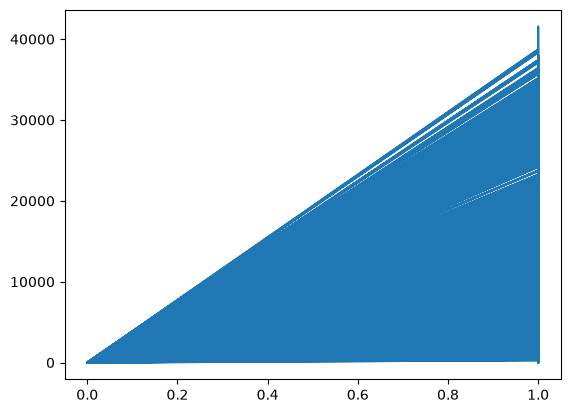

In [20]:
plt.plot(df['Open'], df['Sales'])

In [21]:
np.sum(df['Sales'])

np.int64(5873180623)

<Axes: title={'center': 'Average Sales by Open Status'}, xlabel='DayOfWeek'>

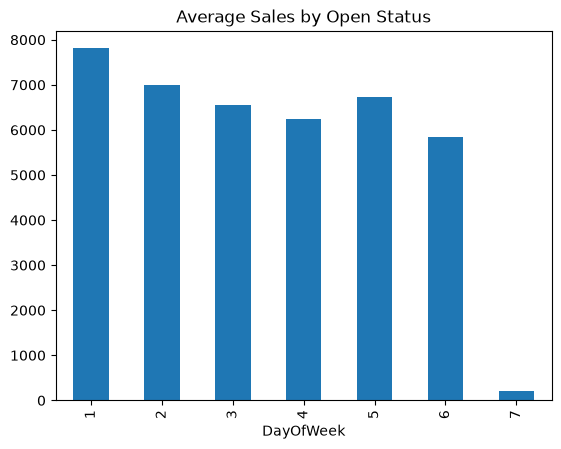

In [22]:
df.groupby('DayOfWeek')['Sales'].mean().plot(kind='bar', title='Average Sales by Open Status')

<Axes: title={'center': 'Average Sales by Open Status'}, xlabel='StateHoliday'>

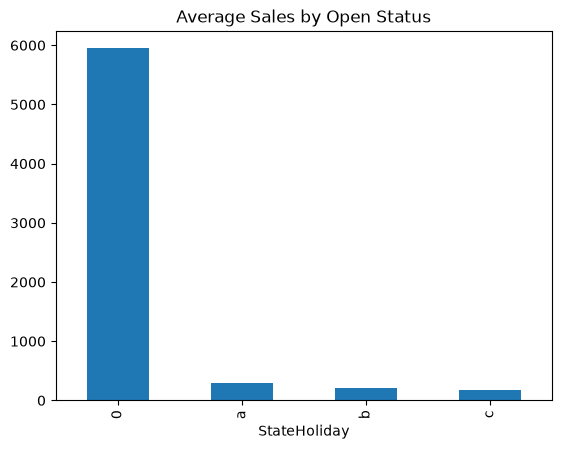

In [23]:
df.groupby('StateHoliday')['Sales'].mean().plot(kind='bar', title='Average Sales by Open Status')

In [24]:
df['StateHoliday'].unique()

<StringArray>
['0', 'a', 'b', 'c']
Length: 4, dtype: str

In [25]:

df[df['StateHoliday']=='0']['Sales'].mean()

np.float64(5947.48389255688)

In [26]:
df[df['StateHoliday']=='c']['Sales'].mean()


np.float64(168.7331707317073)

In [27]:
df[df['StateHoliday']=='b']['Sales'].mean()

np.float64(214.31150971599402)

In [28]:
df[df['StateHoliday']=='a']['Sales'].mean()

np.float64(290.7356860809477)

In [29]:
df[df['SchoolHoliday']==1]['Sales'].mean()

np.float64(6476.522207119706)

In [30]:
df[df['DayOfWeek']==7]['SchoolHoliday'].unique()

array([0, 1])

<Axes: title={'center': 'School Holidays by Day of Week'}, xlabel='DayOfWeek'>

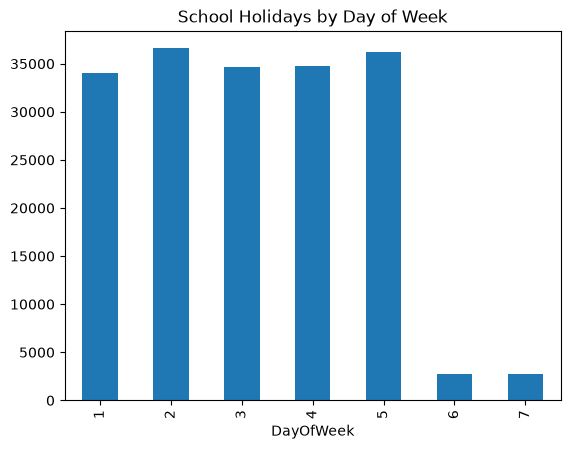

In [31]:
df[df['SchoolHoliday'] == 1].groupby('DayOfWeek').size().plot(kind='bar', title='School Holidays by Day of Week')


<Axes: title={'center': 'Average Sales by Day of Week'}, xlabel='DayOfWeek'>

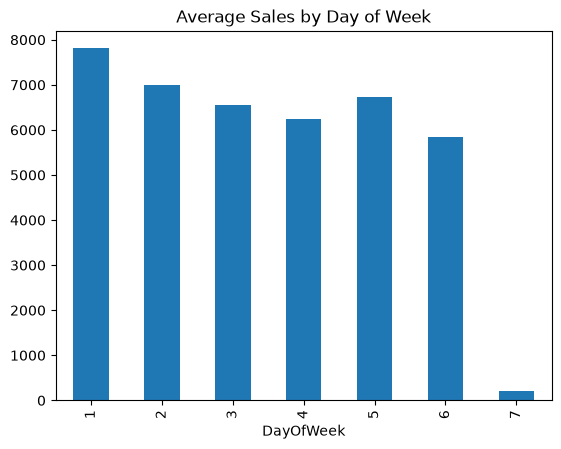

In [43]:
df.groupby('DayOfWeek')['Sales'].mean().plot(kind='bar', title='Average Sales by Day of Week')

<Axes: title={'center': 'Average Sales by Open Status'}, xlabel='DayOfWeek'>

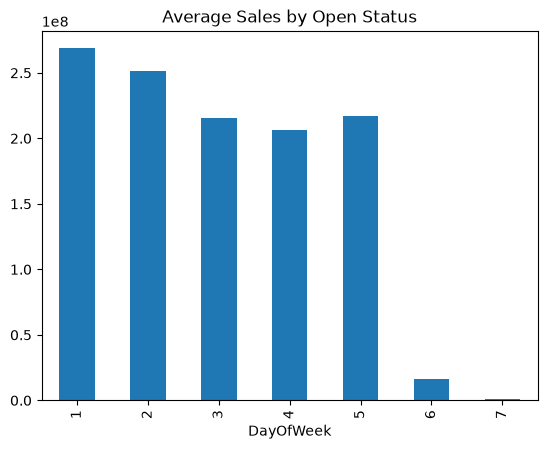

In [32]:
df[df['SchoolHoliday']==1].groupby('DayOfWeek')['Sales'].sum().plot(kind='bar', title='Average Sales by Open Status')

In [33]:
df.describe()

,Store,DayOfWeek,Sales,Customers,Open,Promo,SchoolHoliday,dates
count,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1017209
mean,5.584297e+02,3.998341e+00,5.773819e+03,6.331459e+02,8.301067e-01,3.815145e-01,1.786467e-01,2014-04-11 01:30:42.846062
min,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2013-01-01 00:00:00
25%,2.800000e+02,2.000000e+00,3.727000e+03,4.050000e+02,1.000000e+00,0.000000e+00,0.000000e+00,2013-08-17 00:00:00
50%,5.580000e+02,4.000000e+00,5.744000e+03,6.090000e+02,1.000000e+00,0.000000e+00,0.000000e+00,2014-04-02 00:00:00
75%,8.380000e+02,6.000000e+00,7.856000e+03,8.370000e+02,1.000000e+00,1.000000e+00,0.000000e+00,2014-12-12 00:00:00
max,1.115000e+03,7.000000e+00,4.155100e+04,7.388000e+03,1.000000e+00,1.000000e+00,1.000000e+00,2015-07-31 00:00:00
std,3.219087e+02,1.997391e+00,3.849926e+03,4.644117e+02,3.755392e-01,4.857586e-01,3.830564e-01,NaN


<Axes: title={'center': 'Average Sales by State Holiday'}, xlabel='StateHoliday'>

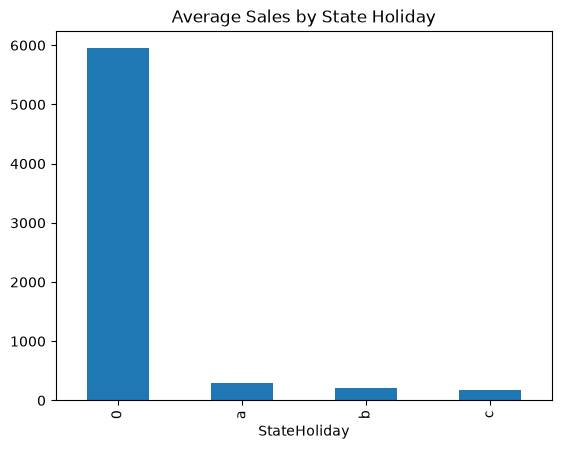

In [34]:
df.groupby('StateHoliday')['Sales'].mean().plot(kind='bar', title='Average Sales by State Holiday')

<Axes: title={'center': 'Average Sales by School Holiday'}, xlabel='SchoolHoliday'>

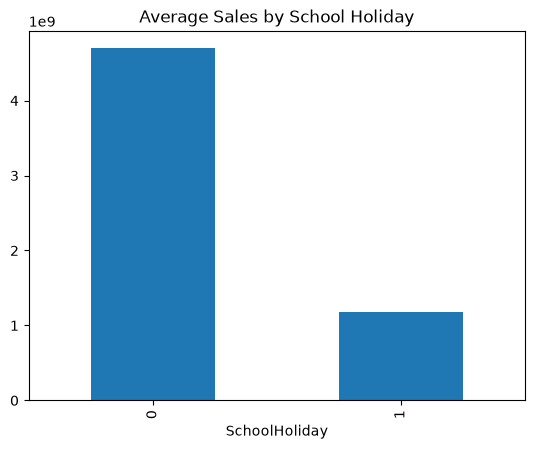

In [35]:
df.groupby('SchoolHoliday')['Sales'].sum().plot(kind='bar', title='Average Sales by School Holiday')

In [36]:
df2=pd.read_csv(r'D:\DATA science projects\RossmanStoreSales\datasets\store.csv')

In [37]:
df2.head()

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [38]:
df2['PromoInterval'].unique()

<StringArray>
[nan, 'Jan,Apr,Jul,Oct', 'Feb,May,Aug,Nov', 'Mar,Jun,Sept,Dec']
Length: 4, dtype: str

In [39]:
import numpy as np
import pandas as pd

mapping = {
    'Jan,Apr,Jul,Oct': 'Jan',
    'Feb,May,Aug,Nov': 'Feb',
    'Mar,Jun,Sept,Dec': 'Mar',
}

df2['PromoInterval'] = df2['PromoInterval'].replace(mapping)


In [40]:
df2.PromoInterval.unique()

<StringArray>
[nan, 'Jan', 'Feb', 'Mar']
Length: 4, dtype: str

In [41]:
df2.head()

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,Jan
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,Jan
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [42]:
df.join(df2, on='Store', how='left').groupby('PromoInterval')['Sales'].mean().plot(kind='bar', title='Average Sales by Promo Interval')

ValueError: columns overlap but no suffix specified: Index(['Store'], dtype='str')

<Axes: title={'center': 'Average Sales by Promo Interval'}, xlabel='PromoInterval'>

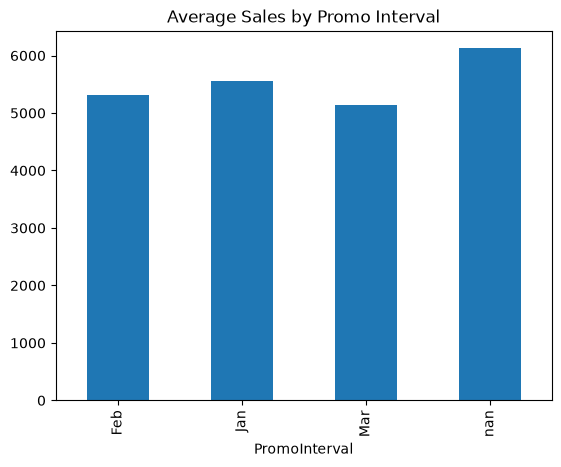

In [ ]:
pd.merge(df, df2, on='Store', how='left').groupby('PromoInterval', dropna=False)['Sales'].mean().plot(kind='bar', title='Average Sales by Promo Interval')

<Axes: title={'center': 'Average Sales by Promo Interval'}, xlabel='Promo2SinceWeek'>

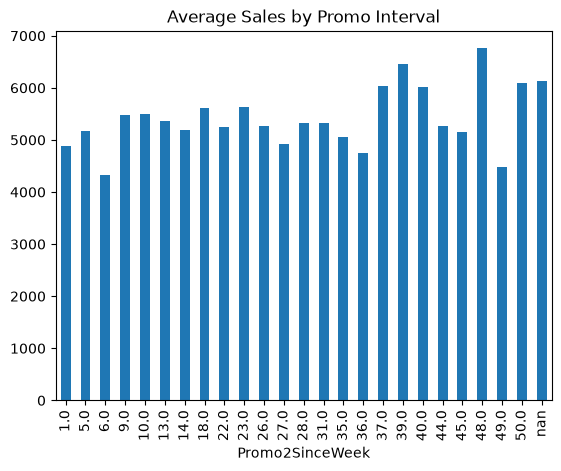

In [ ]:
pd.merge(df, df2, on='Store', how='left').groupby('Promo2SinceWeek', dropna=False)['Sales'].mean().plot(kind='bar', title='Average Sales by Promo Interval')

<Axes: title={'center': 'Average Sales by Promo Interval'}, xlabel='Promo2SinceYear'>

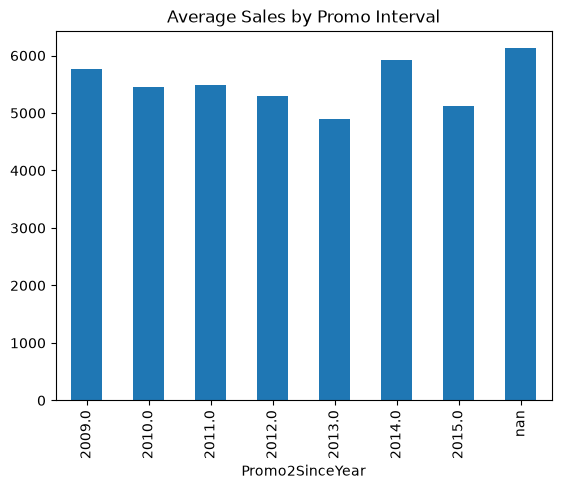

In [ ]:
pd.merge(df, df2, on='Store', how='left').groupby('Promo2SinceYear', dropna=False)['Sales'].mean().plot(kind='bar', title='Average Sales by Promo Interval')

<Axes: title={'center': 'Average Sales by Promo Interval'}, xlabel='CompetitionOpenSinceYear'>

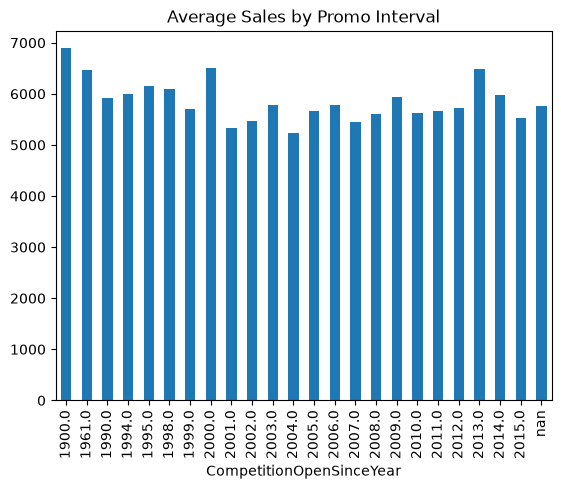

In [ ]:
pd.merge(df, df2, on='Store', how='left').groupby('CompetitionOpenSinceYear', dropna=False)['Sales'].mean().plot(kind='bar', title='Average Sales by Promo Interval')

<Axes: title={'center': 'Average Sales by Promo Interval'}, xlabel='CompetitionDistance'>

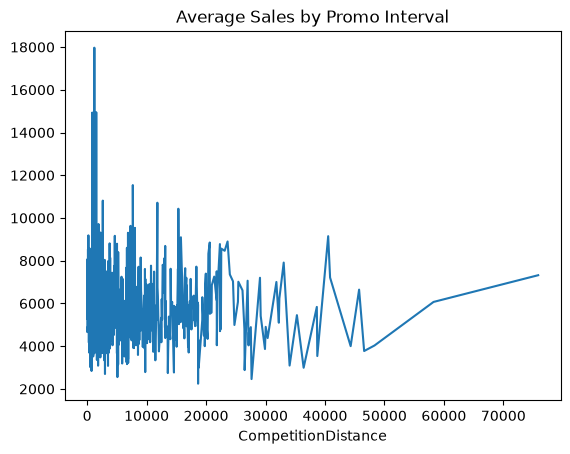

In [ ]:
pd.merge(df, df2, on='Store', how='left').groupby('CompetitionDistance', dropna=False)['Sales'].mean().plot(kind='line', title='Average Sales by Promo Interval')

<Axes: title={'center': 'Average Sales by Competition Distance'}, xlabel='CompetitionDistance'>

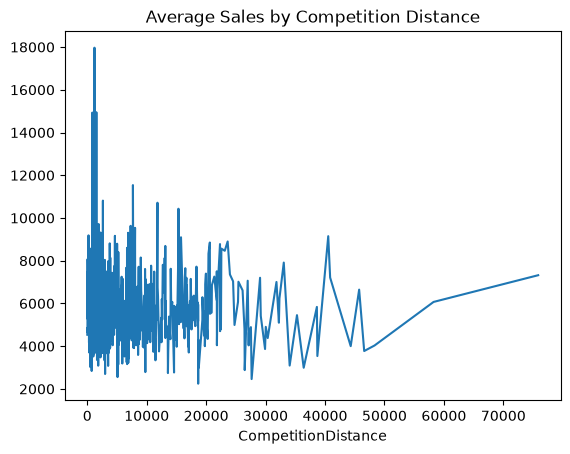

In [ ]:
(
    pd.merge(df, df2, on='Store', how='left')
    .assign(CompetitionDistance=lambda x: x['CompetitionDistance'].fillna(-1))
    .groupby('CompetitionDistance')['Sales'].mean()
    .sort_index()
    .plot(kind='line', title='Average Sales by Competition Distance')
)


<Axes: title={'center': 'Average Sales by Competition Open Month & StoreType'}, xlabel='CompetitionOpenSinceMonth'>

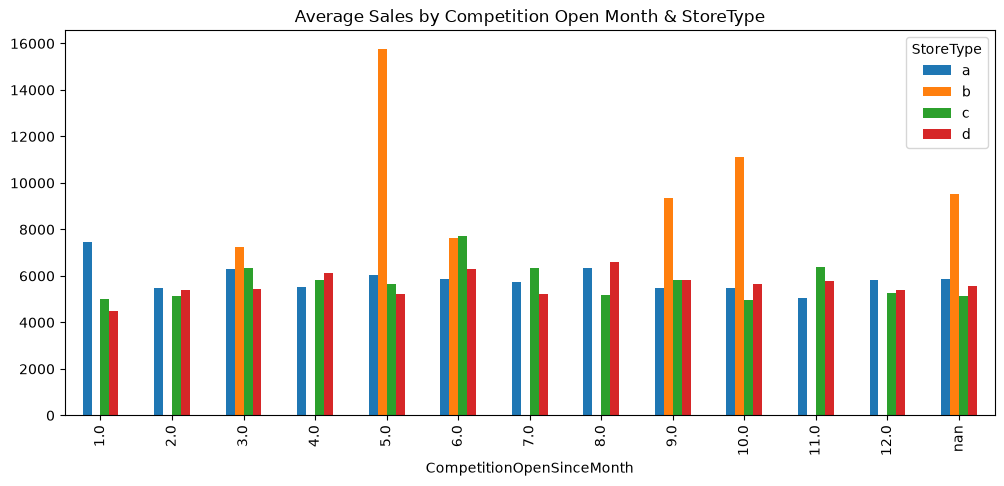

In [51]:
(
    pd.merge(df, df2, on='Store', how='left')
    .groupby(['CompetitionOpenSinceMonth', 'StoreType'], dropna=False)['Sales']
    .mean()  # Total sales ke liye .sum() use karein
    .unstack()
    .plot(kind='bar', figsize=(12, 5), title='Average Sales by Competition Open Month & StoreType')
)


In [ ]:
(
    pd.merge(df, df2, on='Store', how='left')
    .groupby('CompetitionDistance', dropna=False)['Sales'].mean()
    .sort_index(na_position='first')
)


CompetitionDistance
NaN        4535.892884
20.0       4861.790870
30.0       4659.587470
40.0       6212.659448
50.0       8072.697452
              ...     
45740.0    6646.681529
46590.0    3773.877919
48330.0    4032.547771
58260.0    6071.001062
75860.0    7321.466030
Name: Sales, Length: 655, dtype: float64

<Axes: title={'center': 'Average Sales by Promo Interval'}, xlabel='CompetitionOpenSinceMonth'>

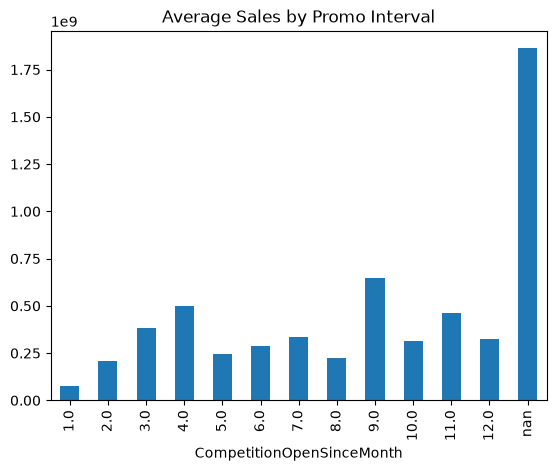

In [ ]:
pd.merge(df, df2, on='Store', how='left').groupby('CompetitionOpenSinceMonth', dropna=False)['Sales'].sum().plot(kind='bar', title='Average Sales by Promo Interval')


<Axes: title={'center': 'Average Sales by Promo Interval'}, xlabel='Assortment'>

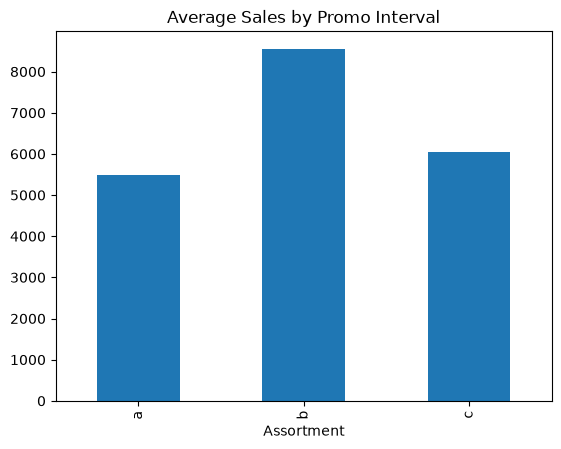

In [ ]:
pd.merge(df, df2, on='Store', how='left').groupby('Assortment', dropna=False)['Sales'].mean().plot(kind='bar', title='Average Sales by Promo Interval')


<Axes: title={'center': 'Average Sales by Competition Open Month & Assortment'}, xlabel='CompetitionOpenSinceMonth'>

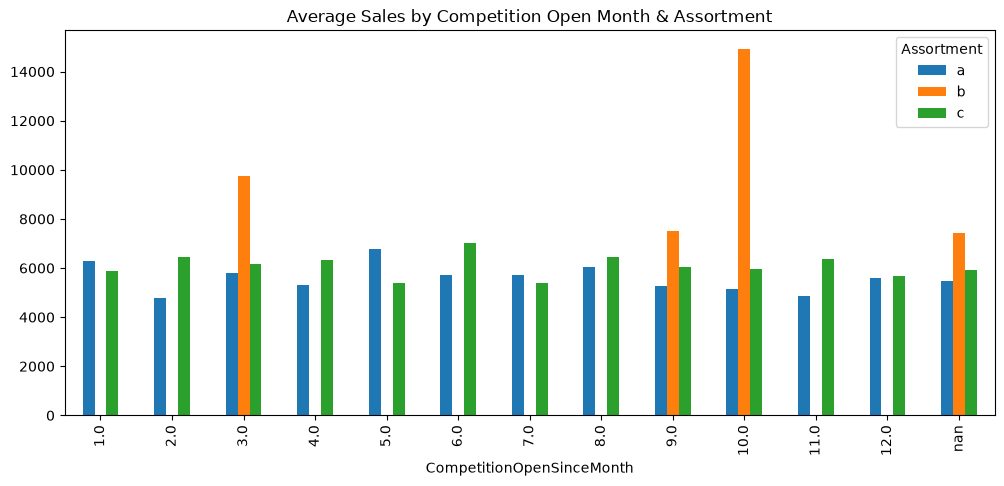

In [49]:
(
    pd.merge(df, df2, on='Store', how='left')
    .groupby(['CompetitionOpenSinceMonth', 'Assortment'], dropna=False)['Sales']
    .mean()  # Use .sum() if you want total sales instead of average
    .unstack()
    .plot(kind='bar', figsize=(12, 5), title='Average Sales by Competition Open Month & Assortment')
)


<Axes: title={'center': 'Average Sales by Competition Open Month & Assortment'}, xlabel='CompetitionOpenSinceMonth'>

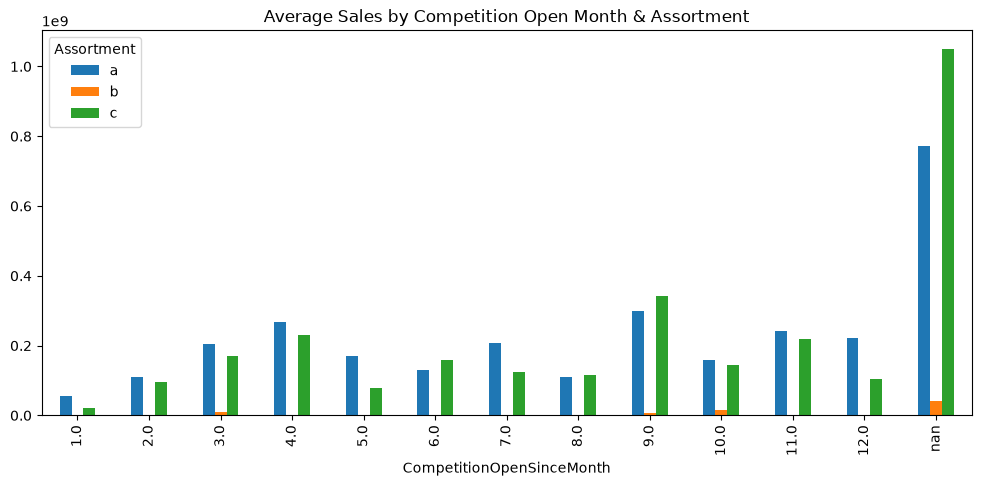

In [50]:
(
    pd.merge(df, df2, on='Store', how='left')
    .groupby(['CompetitionOpenSinceMonth', 'Assortment'], dropna=False)['Sales']
    .sum()  # Use .sum() if you want total sales instead of average
    .unstack()
    .plot(kind='bar', figsize=(12, 5), title='Average Sales by Competition Open Month & Assortment')
)


<Axes: title={'center': 'Average Sales by Promo Interval'}, xlabel='StoreType'>

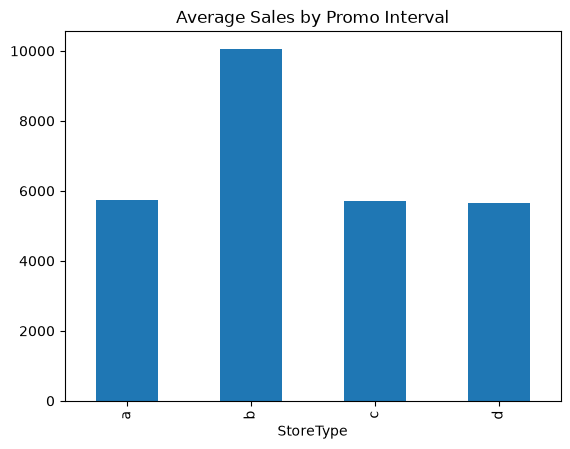

In [ ]:
pd.merge(df, df2, on='Store', how='left').groupby('StoreType', dropna=False)['Sales'].mean().plot(kind='bar', title='Average Sales by Promo Interval')


In [44]:
df[df['DayOfWeek']==6].head()

,Store,DayOfWeek,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,dates
6690,1,6,4364,500,1,0,0,0,2015-07-25
6691,2,6,2512,316,1,0,0,0,2015-07-25
6692,3,6,3878,412,1,0,0,0,2015-07-25
6693,4,6,9322,1219,1,0,0,0,2015-07-25
6694,5,6,2030,228,1,0,0,0,2015-07-25


<Axes: title={'center': 'Average Sales by Day of Week'}, xlabel='DayOfWeek'>

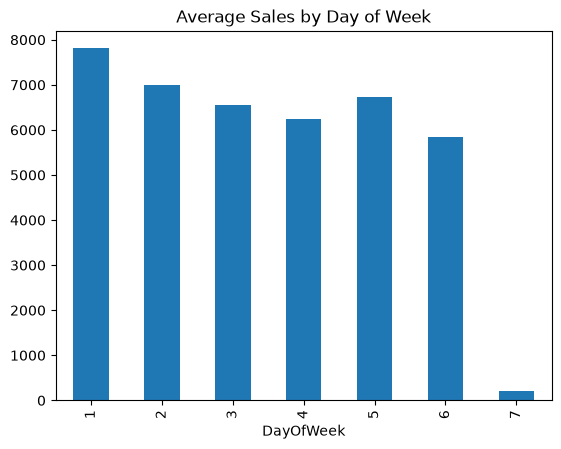

In [45]:
df.groupby("DayOfWeek")["Sales"].mean().plot(kind='bar', title='Average Sales by Day of Week')

<Axes: title={'center': 'Average Sales by Day of Week'}, xlabel='DayOfWeek'>

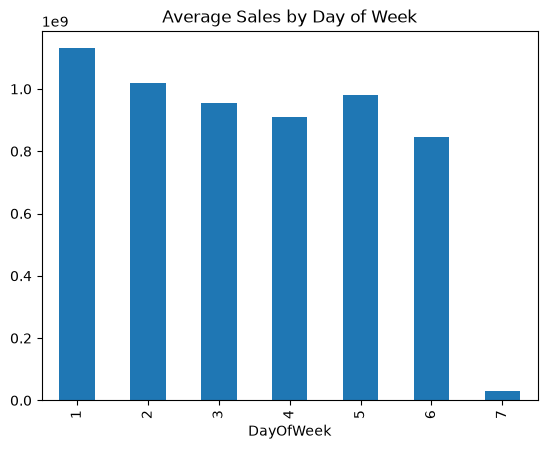

In [46]:
df.groupby("DayOfWeek")["Sales"].sum().plot(kind='bar', title='Average Sales by Day of Week')

<Axes: title={'center': 'Average Sales on School Holidays'}, xlabel='DayOfWeek'>

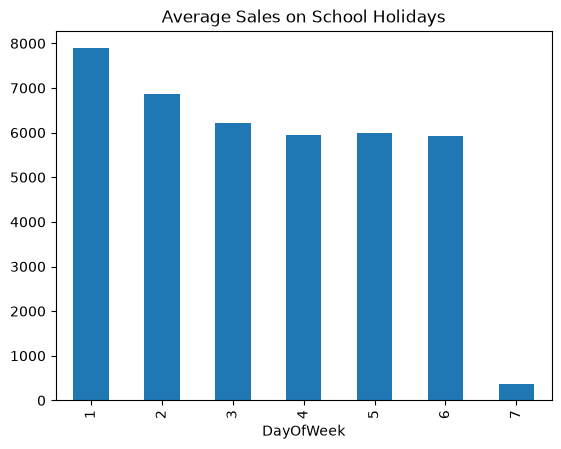

In [47]:
df[df['SchoolHoliday'] == 1].groupby('DayOfWeek')['Sales'].mean().plot(kind='bar', title='Average Sales on School Holidays')


<Axes: title={'center': 'Average Sales on School Holidays'}, xlabel='DayOfWeek'>

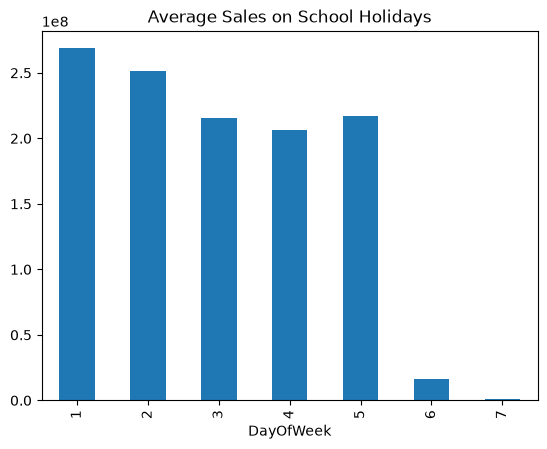

In [48]:
df[df['SchoolHoliday'] == 1].groupby('DayOfWeek')['Sales'].sum().plot(kind='bar', title='Average Sales on School Holidays')


<Axes: title={'center': 'Average Number of Customers by Day of Week'}, xlabel='DayOfWeek'>

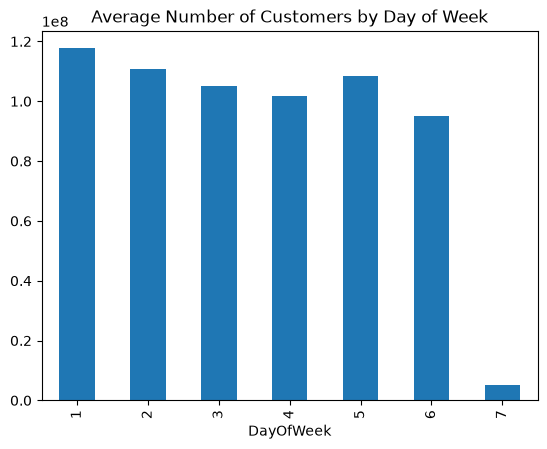

In [53]:
df.groupby('DayOfWeek')['Customers'].sum().plot(kind='bar', title='Average Number of Customers by Day of Week')

<Axes: title={'center': 'Average Number of Customers on School Holidays by Day of Week'}, xlabel='DayOfWeek'>

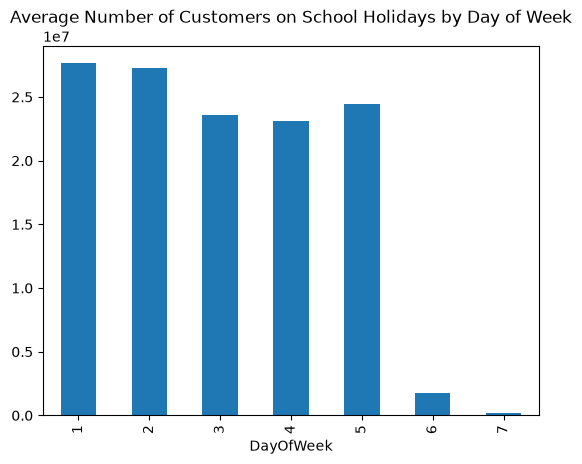

In [55]:
df[df['SchoolHoliday']==1].groupby('DayOfWeek')['Customers'].sum().plot(kind='bar', title='Average Number of Customers on School Holidays by Day of Week')

In [61]:
df[df['StateHoliday'] == 'c']['dates'].nunique()

4

In [65]:
df[(df['StateHoliday'] == 'c') & (df['Customers'] > 0)]


,Store,DayOfWeek,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,dates
241126,85,5,9741,1161,1,0,c,1,2014-12-26
241267,259,5,17597,2544,1,0,c,1,2014-12-26
241270,262,5,32169,4468,1,0,c,1,2014-12-26
241281,274,5,7818,1412,1,0,c,1,2014-12-26
241298,299,5,1800,190,1,0,c,1,2014-12-26
...,...,...,...,...,...,...,...,...,...
617657,733,3,12223,2335,1,0,c,1,2013-12-25
617693,769,3,10033,2055,1,0,c,1,2013-12-25
617872,948,3,7138,1320,1,0,c,1,2013-12-25
618005,1081,3,1929,335,1,0,c,1,2013-12-25


In [67]:
df[(df['StateHoliday'] == 'c') & (df['Customers'] > 0)]['Sales'].sum()/df[(df['StateHoliday'] == 'c') & (df['Customers'] > 0)]['Customers'].sum()


np.float64(6.209271642058969)

In [59]:
df[df['StateHoliday'] == 'c']['Customers'].sum()/df[df['StateHoliday'] == 'c'].shape[0]

np.float64(27.17439024390244)

In [58]:
df[df['StateHoliday'] == 'c']['Sales'].mean()

np.float64(168.7331707317073)